# 03 — Variables de pluie : comparer CHIRPS et IMERG, construire les variables

**Objectifs**
1. Disposer d'une fonction d'extraction de pluie quotidienne depuis Earth Engine (CHIRPS ou IMERG).
2. Comparer les deux produits sur l'emprise (corrélation, biais, accord sur les fortes pluies).
3. Construire les variables du modèle B : cumuls 1, 3, 7 jours et indice de pluie antérieure.
4. Sélectionner les plus fortes pluies pour choisir les dates radar à étiqueter.

**Statut**
- Les parties 1-2 (Earth Engine) **n'ont pas été exécutées** ici.
- La partie 3 utilise des pluies **fictives** pour montrer le fonctionnement ; elles ne décrivent pas le climat de Lomé.

Ce notebook ferme la ligne « CHIRPS ou IMERG ? » de `docs/11_verifications_semaine1.md`.

In [1]:
import sys, json, math
from pathlib import Path

# Racine du dépôt : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine.
RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))  # repli si `pip install -e .` n'a pas été fait

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentinelle_lome.config import charger_config, charger_evenements

cfg = charger_config()
evts = charger_evenements()
print("Racine du dépôt :", RACINE)

Racine du dépôt : /home/claude/sentinelle-lome


In [2]:
from sentinelle_lome.processing.features import cumuls_pluie, evenements_pluvieux, indice_pluie_anterieure

## 1. Extraction depuis Earth Engine *(non exécutée)*

Identifiants de collection lus dans `configs/projet.yaml` : `UCSB-CHG/CHIRPS/DAILY` et `NASA/GPM_L3/IMERG_V07`.

**Points à VÉRIFIER avant d'utiliser les chiffres :**
- bande et unités d'IMERG (le facteur 0,5 ci-dessous suppose des intensités en mm/h sur des pas de 30 minutes) ;
- disponibilité de la période demandée pour chaque produit ;
- échelle de réduction (résolution native différente entre les deux produits).

In [3]:
UTILISER_EE = False
PROJET_GEE = "votre-projet"

def serie_quotidienne_ee(ee, aoi, produit: str, debut: str, fin: str) -> pd.DataFrame:
    """Pluie moyenne sur l'emprise, par jour. `produit` ∈ {"CHIRPS", "IMERG"}. Limiter à ~1 an par appel."""
    col_id = cfg["pluie"]["collections"][produit]
    jours = [d.strftime("%Y-%m-%d") for d in pd.date_range(debut, fin, freq="D")]

    def calc(d):
        d = ee.Date(d)
        jour = ee.ImageCollection(col_id).filterDate(d, d.advance(1, "day")).select("precipitation")
        img = jour.sum().multiply(0.5) if produit == "IMERG" else jour.sum()   # facteur IMERG : À VÉRIFIER
        echelle = 10000 if produit == "IMERG" else 5000
        val = img.reduceRegion(ee.Reducer.mean(), aoi, echelle).get("precipitation")
        return ee.Feature(None, {"date": d.format("YYYY-MM-dd"), "pluie_mm": val})

    fc = ee.FeatureCollection(ee.List(jours).map(calc))
    df = pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])
    df["date"] = pd.to_datetime(df["date"])
    df["source"] = produit
    return df

if UTILISER_EE:
    import ee
    ee.Initialize(project=PROJET_GEE)
    lon_min, lat_min, lon_max, lat_max = cfg["zone_etude"]["emprise_provisoire"]
    aoi = ee.Geometry.Rectangle([lon_min, lat_min, lon_max, lat_max])
    dossier = RACINE / "data" / "raw"
    dossier.mkdir(parents=True, exist_ok=True)
    periode = ("2025-01-01", "2025-12-31")     # une année par appel ; boucler pour les années précédentes
    for produit in ("CHIRPS", "IMERG"):
        serie = serie_quotidienne_ee(ee, aoi, produit, *periode)
        serie.to_csv(dossier / f"pluie_{produit.lower()}.csv", index=False)
        print(produit, len(serie), "jours enregistrés")
else:
    print("UTILISER_EE = False : aucune extraction réelle effectuée.")

UTILISER_EE = False : aucune extraction réelle effectuée.


## 2. Comparaison CHIRPS / IMERG *(si les CSV existent)*

Critères pour trancher (à reporter dans `projet.yaml`, clé `pluie.produit_principal`) :
- **Latence** : délai de disponibilité par rapport au jour courant (indispensable pour une alerte).
- **Accord sur les fortes pluies** : les jours les plus pluvieux doivent coïncider avec les événements connus (juin 2026).
- **Biais** et **corrélation** globaux.

Aucune vérité terrain pluviométrique n'est supposée disponible ; l'idéal est de comparer aussi à des pluviomètres (à demander à l'ANAMET ou à l'ANPC : [À CONFIRMER]).

In [4]:
f_ch, f_im = RACINE / "data" / "raw" / "pluie_chirps.csv", RACINE / "data" / "raw" / "pluie_imerg.csv"
if f_ch.exists() and f_im.exists():
    ch = pd.read_csv(f_ch, parse_dates=["date"]).rename(columns={"pluie_mm": "chirps"})[["date", "chirps"]]
    im = pd.read_csv(f_im, parse_dates=["date"]).rename(columns={"pluie_mm": "imerg"})[["date", "imerg"]]
    j = ch.merge(im, on="date").dropna()
    print("Jours communs :", len(j))
    print("Corrélation (Pearson) :", round(j["chirps"].corr(j["imerg"]), 3))
    print("Biais moyen (IMERG − CHIRPS) :", round((j["imerg"] - j["chirps"]).mean(), 2), "mm/jour")
    top_ch = set(evenements_pluvieux(j.rename(columns={"chirps": "pluie_mm"}), n=15)["date"])
    top_im = set(evenements_pluvieux(j.rename(columns={"imerg": "pluie_mm"}), n=15)["date"])
    print("Fortes pluies communes (top 15 de chaque) :", len(top_ch & top_im))
else:
    print("CSV de pluie absents (data/raw/pluie_chirps.csv, pluie_imerg.csv) : comparaison non exécutée.")

CSV de pluie absents (data/raw/pluie_chirps.csv, pluie_imerg.csv) : comparaison non exécutée.


## 3. Variables du modèle B (démonstration sur pluie FICTIVE)

On simule trois années de pluie quotidienne pour deux zones, avec deux saisons plus humides **inventées** pour l'exemple. Le but est de montrer :
- les **cumuls glissants** (`cumuls_pluie`) ;
- l'**indice de pluie antérieure** `API_t = k·API_{t-1} + P_t` (`indice_pluie_anterieure`) ;
- la **sélection d'événements** (`evenements_pluvieux`).

In [5]:
rng = np.random.default_rng(7)
jours = pd.date_range("2023-01-01", "2025-12-31", freq="D")
doy = jours.dayofyear.to_numpy()
# profil saisonnier FICTIF à deux pics (jour de l'année ~ 150 et ~ 280)
p_pluie = 0.08 + 0.35 * np.exp(-((doy - 150) / 35) ** 2) + 0.25 * np.exp(-((doy - 280) / 25) ** 2)

def serie(zone, facteur):
    est_humide = rng.uniform(size=len(jours)) < p_pluie
    mm = np.where(est_humide, rng.gamma(0.8, 14.0 * facteur, len(jours)), 0.0)
    return pd.DataFrame({"zone_id": zone, "date": jours, "pluie_mm": mm})

pluie = pd.concat([serie("zone_A", 1.0), serie("zone_B", 1.2)], ignore_index=True)
pluie.groupby("zone_id")["pluie_mm"].agg(["sum", "max"]).round(0)

,sum,max
zone_id,,
zone_A,2286.0,67.0
zone_B,2470.0,85.0


In [6]:
fen = cfg["pluie"]["fenetres_cumul_jours"]
k = cfg["pluie"]["k_pluie_anterieure"]
vars_pluie = cumuls_pluie(pluie, fenetres=fen)
vars_pluie["api"] = vars_pluie.groupby("zone_id", group_keys=False)["pluie_mm"].apply(
    lambda s: indice_pluie_anterieure(s, k=k))
print("Fenêtres de cumul :", fen, "| k =", k, "(k : À CALIBRER)")
vars_pluie.head(8).round({c: 1 for c in vars_pluie.select_dtypes("number").columns})

Fenêtres de cumul : [1, 3, 7] | k = 0.85 (k : À CALIBRER)


,zone_id,date,pluie_mm,pluie_cumul_1j,pluie_cumul_3j,pluie_cumul_7j,api
0,zone_A,2023-01-01,0.0,0.0,NaN,NaN,0.0
1,zone_A,2023-01-02,0.0,0.0,NaN,NaN,0.0
2,zone_A,2023-01-03,0.0,0.0,0.0,NaN,0.0
3,zone_A,2023-01-04,0.0,0.0,0.0,NaN,0.0
4,zone_A,2023-01-05,0.0,0.0,0.0,NaN,0.0
5,zone_A,2023-01-06,0.0,0.0,0.0,NaN,0.0
6,zone_A,2023-01-07,8.3,8.3,8.3,8.3,8.3
7,zone_A,2023-01-08,0.0,0.0,8.3,8.3,7.1


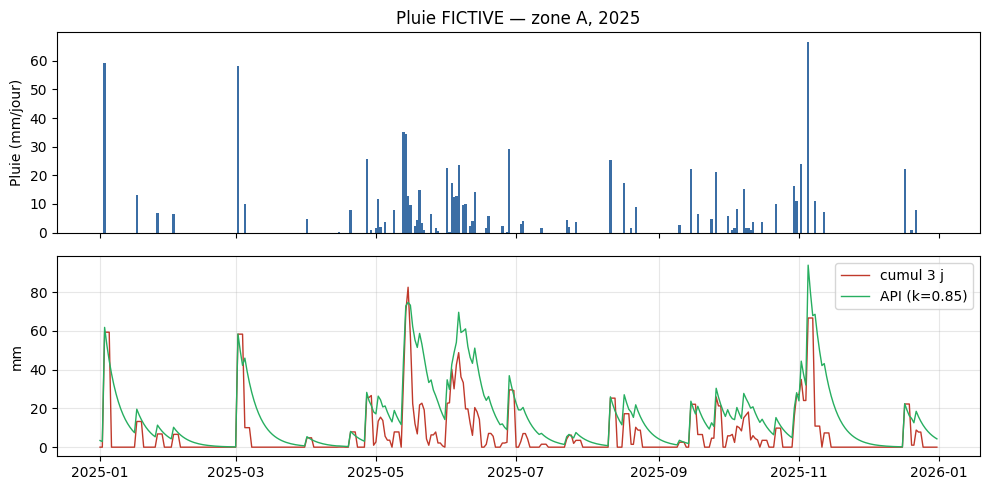

In [7]:
za = vars_pluie[(vars_pluie["zone_id"] == "zone_A") & (vars_pluie["date"].dt.year == 2025)]
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].bar(za["date"], za["pluie_mm"], width=1.0, color="#3b6ea5")
ax[0].set_ylabel("Pluie (mm/jour)")
ax[0].set_title("Pluie FICTIVE — zone A, 2025")
ax[1].plot(za["date"], za["pluie_cumul_3j"], label="cumul 3 j", color="#c0392b", lw=1)
ax[1].plot(za["date"], za["api"], label=f"API (k={k})", color="#27ae60", lw=1)
ax[1].set_ylabel("mm"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Sélection des dates à étiqueter

Les plus fortes pluies (cumul sur 3 jours, espacées d'au moins 3 jours) désignent les **dates radar candidates** à étiqueter (`docs/04`, étape 1). Sur de vraies données, croiser avec les images Sentinel-1 réellement disponibles (notebook 01, section 3) et avec les événements connus de `evenements.yaml`.

In [8]:
za_all = pluie[pluie["zone_id"] == "zone_A"]
top = evenements_pluvieux(za_all, n=8, separation_jours=3, cumul_jours=3)
top["date"] = top["date"].dt.date
top.round(1)

,date,cumul_mm
0,2025-05-15,82.5
1,2023-04-25,75.1
2,2025-11-05,66.6
3,2023-10-20,62.4
4,2025-01-04,59.3
5,2025-03-04,58.3
6,2024-07-08,56.0
7,2024-10-23,55.0


## 4. Résumé des décisions attendues de ce notebook

| Décision | Où la consigner |
|---|---|
| Produit de pluie principal (CHIRPS ou IMERG) | `configs/projet.yaml`, clé `pluie.produit_principal`, et `docs/02` |
| Latence réelle et utilisabilité pour l'alerte | `docs/02` et `docs/06` |
| Valeur de `k` pour l'indice de pluie antérieure | `configs/projet.yaml`, après calibration |
| Liste des dates radar à étiqueter | `configs/evenements.yaml` |

**Prochaine étape** : variables de terrain (HAND, pente) et premières tables silver avec Spark (notebooks 04 à 06 du planning).